# **01 - Exploratory Data Analysis**
Kompetisi: *Structural Damage Classification* (klasifikasi multi-kelas `damage_grade` Grade 1-5).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

os.makedirs("../reports/figures", exist_ok=True)
sns.set_style("whitegrid")

# **1. Read Dataset**

In [2]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (533465, 17) | Test: (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

Catatan: pada data ini `superstructure` berupa **satu kolom kategorik** (bukan flag boolean `has_superstructure_*` seperti pada `metadata.csv`).

# **2. Quick EDA**
### Duplikasi data

In [4]:
print("Duplikat baris penuh :", train.duplicated().sum())
print("Duplikat building_id  :", train["building_id"].duplicated().sum())
print("Duplikat fitur (tanpa id):", train.drop(columns="building_id").duplicated().sum())

Duplikat baris penuh : 0
Duplikat building_id  : 0


Duplikat fitur (tanpa id): 22281


Tidak ada duplikasi `building_id`. Baris dengan fitur yang sama (tanpa ID) adalah bangunan berbeda yang kebetulan mirip, sehingga **tidak di-drop**.

### Cek missing value

In [5]:
def cek_missing(df):
    return pd.DataFrame({"Jumlah": df.isna().sum(), "Persentase": df.isna().mean() * 100})

cek_missing(train).join(cek_missing(test), rsuffix="_test")

,Jumlah,Persentase,Jumlah_test,Persentase_test
building_id,0,0.0,0.0,0.0
district_id,0,0.0,0.0,0.0
vdcmun_id,0,0.0,0.0,0.0
ward_id,0,0.0,0.0,0.0
count_floors_pre_eq,0,0.0,0.0,0.0
age_building,0,0.0,0.0,0.0
plinth_area_sq_ft,0,0.0,0.0,0.0
height_ft_pre_eq,0,0.0,0.0,0.0
land_surface_condition,0,0.0,0.0,0.0
foundation_type,0,0.0,0.0,0.0


Tidak ada missing value pada train maupun test. Imputer tetap dipasang di pipeline sebagai pengaman.

### Statistika deskriptif

In [6]:
num_cols = ["count_floors_pre_eq", "age_building", "plinth_area_sq_ft", "height_ft_pre_eq"]
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


In [7]:
print("age_building > 100 :", (train.age_building > 100).sum())
print("age_building == 999 :", (train.age_building == 999).sum())
print("height > 60 ft      :", (train.height_ft_pre_eq > 60).sum())
print("floors >= 6         :", (train.count_floors_pre_eq >= 6).sum())

age_building > 100 : 3195
age_building == 999 : 2198
height > 60 ft      : 295
floors >= 6         : 307


Terdapat outlier (`age_building` hingga 999, kemungkinan kode khusus). Pada feature engineering, umur di-*clip* pada 100.

In [8]:
cat_cols = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "superstructure"]
{col: train[col].value_counts().to_dict() for col in cat_cols}

{'land_surface_condition': {'Flat': 442089,
  'Moderate slope': 73944,
  'Steep slope': 17432},
 'foundation_type': {'Mud mortar-Stone/Brick': 440105,
  'Bamboo/Timber': 40167,
  'Cement-Stone/Brick': 27562,
  'RC': 22445,
  'Other': 3186},
 'roof_type': {'Bamboo/Timber-Light roof': 352493,
  'Bamboo/Timber-Heavy roof': 149836,
  'RCC/RB/RBC': 31136},
 'ground_floor_type': {'Mud': 432806,
  'RC': 51146,
  'Brick/Stone': 46264,
  'Timber': 2507,
  'Other': 742},
 'other_floor_type': {'TImber/Bamboo-Mud': 340906,
  'Timber-Planck': 86637,
  'Not applicable': 83103,
  'RCC/RB/RBC': 22819},
 'position': {'Not attached': 423151,
  'Attached-1 side': 90493,
  'Attached-2 side': 18943,
  'Attached-3 side': 878},
 'plan_configuration': {'Rectangular': 511999,
  'Square': 12229,
  'L-shape': 7009,
  'T-shape': 668,
  'Multi-projected': 636,
  'Others': 387,
  'U-shape': 313,
  'E-shape': 99,
  'Building with Central Courtyard': 64,
  'H-shape': 61},
 'superstructure': {'has_superstructure_mud_m

In [9]:
{c: train[c].nunique() for c in ["district_id", "vdcmun_id", "ward_id"]}

{'district_id': 11, 'vdcmun_id': 110, 'ward_id': 945}

### Distribusi fitur numerik

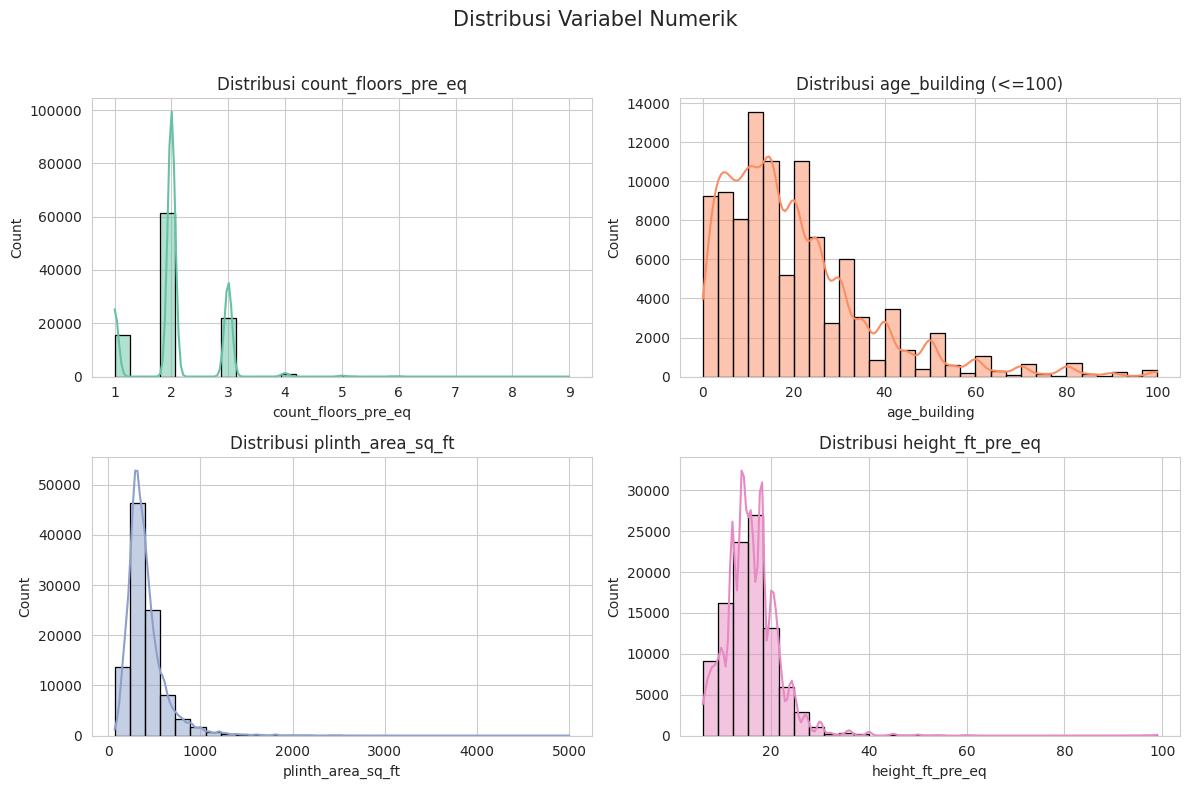

In [10]:
plot_df = train.sample(100_000, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, color in zip(axes.ravel(), num_cols, sns.color_palette("Set2")):
    data = plot_df[plot_df[col] <= (100 if col == "age_building" else plot_df[col].max())][col]
    sns.histplot(data, bins=30, kde=True, color=color, edgecolor="black", ax=ax)
    ax.set_title(f"Distribusi {col}" + (" (<=100)" if col == "age_building" else ""))
plt.suptitle("Distribusi Variabel Numerik", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("../reports/figures/distribusi_numerik.png", dpi=120)
plt.show()

### Distribusi fitur kategorik

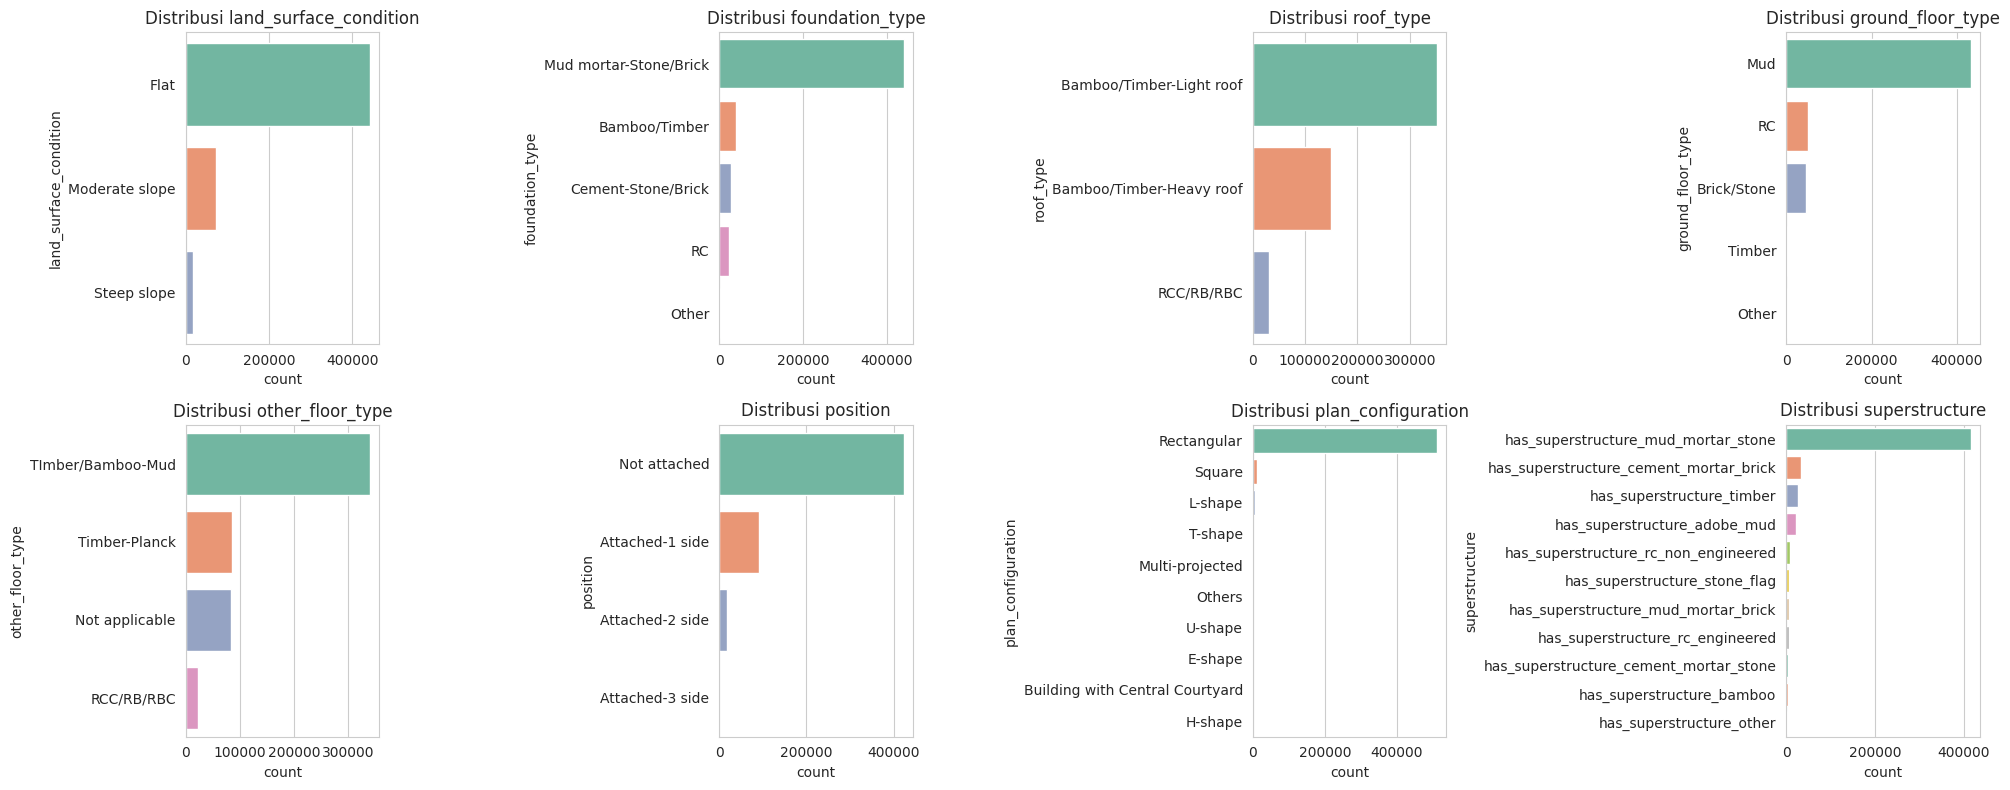

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(y=col, data=train, ax=ax, palette="Set2", order=train[col].value_counts().index)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.savefig("../reports/figures/distribusi_kategorik.png", dpi=110)
plt.show()

### Cek imbalance target

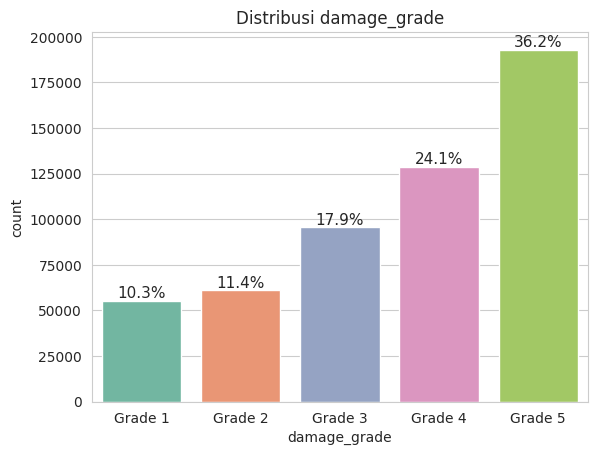

In [12]:
order = sorted(train["damage_grade"].unique())
ax = sns.countplot(x="damage_grade", data=train, order=order, palette="Set2")
for p in ax.patches:
    ax.annotate(f"{100 * p.get_height() / len(train):.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.title("Distribusi damage_grade")
plt.savefig("../reports/figures/distribusi_target.png", dpi=120)
plt.show()

Kelas **tidak seimbang** (Grade 5 mendominasi ~36%, Grade 1 hanya ~10%). Karena itu evaluasi tidak hanya akurasi, tetapi juga F1-macro.

### Hubungan fitur lokasi dengan target

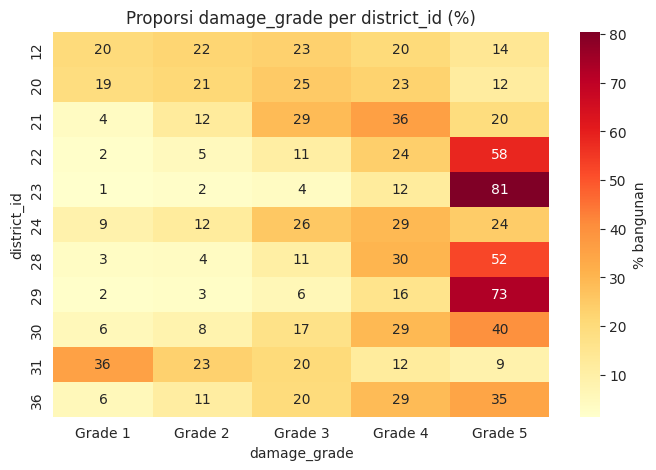

In [13]:
ct = pd.crosstab(train["district_id"], train["damage_grade"], normalize="index") * 100
plt.figure(figsize=(8, 5))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% bangunan"})
plt.title("Proporsi damage_grade per district_id (%)")
plt.savefig("../reports/figures/damage_per_district.png", dpi=120, bbox_inches="tight")
plt.show()

Lokasi sangat menentukan: proporsi Grade 5 berkisar ~9% (district 31) hingga ~81% (district 23). Maka `district_id`, `vdcmun_id`, dan `ward_id` diperlakukan sebagai **fitur kategorik**, bukan angka.

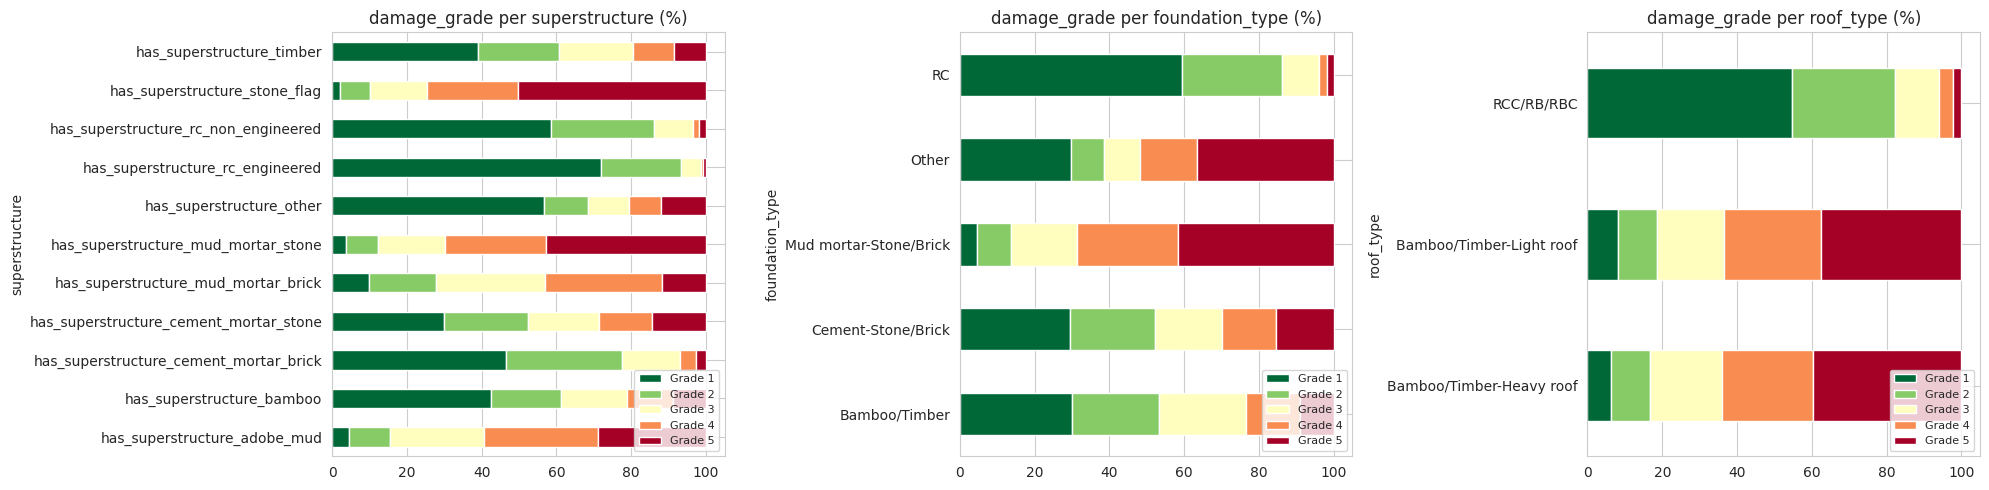

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["superstructure", "foundation_type", "roof_type"]):
    (pd.crosstab(train[col], train["damage_grade"], normalize="index") * 100).plot(
        kind="barh", stacked=True, ax=ax, colormap="RdYlGn_r")
    ax.set_title(f"damage_grade per {col} (%)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("../reports/figures/damage_per_struktur.png", dpi=110)
plt.show()

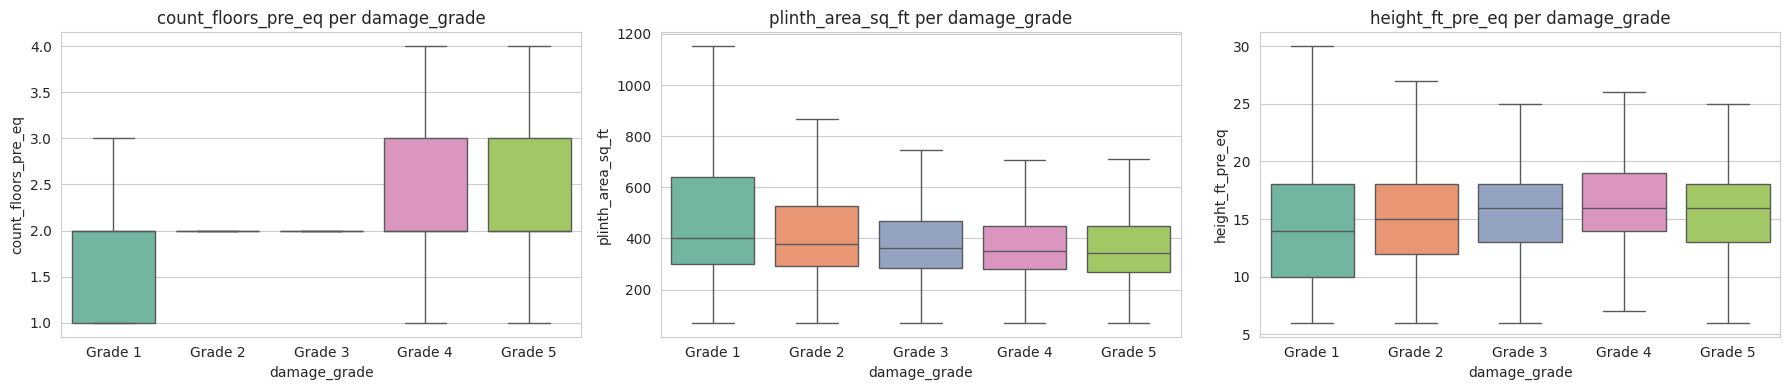

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["count_floors_pre_eq", "plinth_area_sq_ft", "height_ft_pre_eq"]):
    sns.boxplot(x="damage_grade", y=col, data=plot_df, order=order, ax=ax, palette="Set2", showfliers=False)
    ax.set_title(f"{col} per damage_grade")
plt.tight_layout()
plt.show()

### Struktur `building_id`

In [16]:
bid = train["building_id"].astype(str)
print("2 digit pertama == district_id :", (bid.str[:2].astype(int) == train["district_id"]).mean())
print("6 digit pertama == ward_id     :", (bid.str[:6].astype(int) == train["ward_id"]).mean())
print("ID train/test beririsan        :", test["building_id"].isin(train["building_id"]).sum())
print("Ward test yang ada di train    :", test["ward_id"].isin(train["ward_id"]).mean())

2 digit pertama == district_id : 1.0
6 digit pertama == ward_id     : 0.0014733862577676136
ID train/test beririsan        : 0


Ward test yang ada di train    : 1.0


## Kesimpulan EDA
- Tidak ada missing value; `building_id` unik; test tidak punya ID yang bocor dari train.
- Target tidak seimbang (Grade 5 ~36%, Grade 1 ~10%).
- Fitur **lokasi** (district/vdc/ward) paling informatif; semua ward di test juga ada di train.
- Material (`superstructure`, `foundation_type`, `roof_type`) dan jumlah lantai/tinggi ikut berpengaruh.
- Outlier `age_building` (maks. 999) ditangani dengan *clipping*.
- 2 digit pertama `building_id` sama dengan `district_id`; digit lainnya diuji sebagai fitur tambahan saat modeling.